# Task 2 — Player Segment Classification models

Round 1 compares original and combined datasets on the **same stratified 80/20 split**, scored by macro F₁. Saved models are loaded on rerun. Preprocessing is fitted inside each saved Pipeline; Test is read only to check feature schema.

## 1. Load the original saved dataset and validation split

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src" / "pipeline" / "save_data.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
SRC = ROOT / "src"

import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.metrics import f1_score, make_scorer, classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.inspection import permutation_importance
from src.pipeline.random_seed import set_seed
from src.pipeline.save_model import save_model
from src.pipeline.evaluate_model import evaluate_model
from src.pipeline.read_evalutate_summarize import read_evaluation_index

SEED = set_seed()
TARGET, ID, DATA_NAME = "segment", "player_id", "eda_original_v1"
SCORE = make_scorer(f1_score, average="macro", zero_division=0)
CV = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
sns.set_theme(style="whitegrid")

data_card_path = SRC / "task2" / "data" / "eda" / f"{DATA_NAME}.json"
data_card = json.loads(data_card_path.read_text(encoding="utf-8"))
def read_split(split):
    path = SRC / data_card["splits"][split]["path"]
    return pd.read_parquet(path) if data_card["format"] == "parquet" else pd.read_csv(path)
train_df, test_df = read_split("train"), read_split("test")
assert train_df.drop(columns=[TARGET]).columns.tolist() == test_df.columns.tolist()
assert train_df[ID].is_unique and test_df[ID].is_unique
assert train_df[TARGET].notna().all() and set(train_df[TARGET].unique()) == {0, 1, 2, 3}
print("Dataset:", DATA_NAME, "| Train:", len(train_df), "| Test:", len(test_df))

Dataset: eda_original_v1 | Train: 104000 | Test: 25889


In [2]:
feature_cols = test_df.columns.drop(ID).tolist()
X, y = train_df[feature_cols], train_df[TARGET].astype(int)
dev_idx, valid_idx = train_test_split(np.arange(len(y)), test_size=.20,
                                      stratify=y, random_state=SEED)
X_dev, X_valid = X.iloc[dev_idx], X.iloc[valid_idx]
y_dev, y_valid = y.iloc[dev_idx], y.iloc[valid_idx]
assert y_dev.index.intersection(y_valid.index).empty
display(pd.DataFrame({
    "development": y_dev.value_counts().sort_index(),
    "validation": y_valid.value_counts().sort_index(),
    "development_pct": y_dev.value_counts(normalize=True).sort_index().mul(100).round(2),
    "validation_pct": y_valid.value_counts(normalize=True).sort_index().mul(100).round(2),
}))

,development,validation,development_pct,validation_pct
segment,,,,
0,32747,8187,39.36,39.36
1,20827,5207,25.03,25.03
2,16811,4203,20.21,20.21
3,12815,3203,15.40,15.40


## 2. Preprocessing and artifact reuse

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

string_cols = X.select_dtypes(include="object").columns.tolist()
game_mode_col = ["preferred_game_mode"]  # Numeric code for a nominal mode.
numeric_cols = [c for c in feature_cols if c not in string_cols + game_mode_col]
noise_cols = ["random_metric_1", "random_metric_2", "random_metric_3"]
assert len(string_cols) == 10 and len(numeric_cols) == 33
assert set(noise_cols) <= set(numeric_cols)

def make_preprocessor(*, scale=False, drop_noise=False, dataset="original"):
    cols = numeric_cols if dataset == "original" else combined_numeric_cols
    selected_numeric = [c for c in cols if not (drop_noise and c in noise_cols)]
    numeric_steps = [("impute", SimpleImputer(strategy="median", add_indicator=True))]
    if scale:
        numeric_steps.append(("scale", StandardScaler()))
    return ColumnTransformer([
        ("numeric", Pipeline(numeric_steps), selected_numeric),
        ("string", Pipeline([
            ("impute", SimpleImputer(strategy="constant", fill_value="<missing>")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), string_cols),
        ("game_mode", Pipeline([
            ("impute", SimpleImputer(strategy="constant", fill_value=-1)),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), game_mode_col),
    ], remainder="drop", sparse_threshold=0)

SAVE_DIR = SRC / "task2" / "save"
def model_paths(name):
    return SAVE_DIR / f"{name}.joblib", SAVE_DIR / f"{name}.json", SAVE_DIR / f"{name}-evaluation.json"

def load_model(name):
    model_path, card_path, _ = model_paths(name)
    card = json.loads(card_path.read_text(encoding="utf-8"))
    assert card["model_path"] == f"task2/save/{name}.joblib"
    return joblib.load(model_path)

def saved_result(name, *, dataset="original"):
    model_path, card_path, evaluation_path = model_paths(name)
    if not any(p.exists() for p in (model_path, card_path, evaluation_path)):
        return None
    if not model_path.exists() or not card_path.exists():
        raise RuntimeError(f"Incomplete model artifact for {name}")
    model_card = json.loads(card_path.read_text(encoding="utf-8"))
    expected_data_name = DATA_NAME if dataset == "original" else COMBINED_DATA_NAME
    valid_X = X_valid if dataset == "original" else X_valid_combined
    if model_card["data_name"] != expected_data_name:
        raise ValueError(f"{name} is linked to a different dataset")
    if not evaluation_path.exists():
        pred = np.asarray(load_model(name).predict(valid_X)).reshape(-1)
        result = evaluate_model(task=2, name=name, y_true=y_valid, y_pred=pred,
                                card={"split": "stratified holdout 20%", "seed": SEED})
        print("Loaded model and recorded missing evaluation:", name)
        return result
    result = json.loads(evaluation_path.read_text(encoding="utf-8"))
    if result["metric"] != "macro_F1" or result["data_name"] != expected_data_name:
        raise ValueError(f"Inconsistent evaluation for {name}")
    print(f"Loaded {name}: macro F1 = {result['score']:.5f}")
    return result

def record_model(name, model, idea, tuning="none", *, dataset="original"):
    data_name = DATA_NAME if dataset == "original" else COMBINED_DATA_NAME
    valid_X = X_valid if dataset == "original" else X_valid_combined
    save_model(task=2, name=name, model=model, data_name=data_name,
               card={"idea": idea, "seed": SEED, "split": "stratified 80/20", "tuning": tuning})
    pred = np.asarray(model.predict(valid_X)).reshape(-1)
    result = evaluate_model(task=2, name=name, y_true=y_valid, y_pred=pred,
                            card={"split": "held-out validation 20%", "seed": SEED,
                                  "tuning": tuning})
    print(f"Trained {name}: macro F1 = {result['score']:.5f}")
    return result

## 3. Round 1 — initial classifiers

In [4]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

name = "t2_dummy_original_v1"
if saved_result(name) is None:
    model = DummyClassifier(strategy="most_frequent")
    model.fit(X_dev, y_dev)
    record_model(name, model, "Majority-class reference")

Loaded t2_dummy_original_v1: macro F1 = 0.14122


In [5]:
name = "t2_logreg_original_v1"
if saved_result(name) is None:
    model = Pipeline([
        ("preprocess", make_preprocessor(scale=True)),
        ("classifier", LogisticRegression(max_iter=800, class_weight="balanced",
                                          random_state=SEED)),
    ])
    model.fit(X_dev, y_dev)
    record_model(name, model, "Imputation, one-hot encoding, scaling, balanced logistic regression")

Loaded t2_logreg_original_v1: macro F1 = 0.74376


In [6]:
name = "t2_rf_original_v1"
if saved_result(name) is None:
    model = Pipeline([
        ("preprocess", make_preprocessor()),
        ("classifier", RandomForestClassifier(
            n_estimators=150, max_depth=18, min_samples_leaf=5,
            class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)),
    ])
    model.fit(X_dev, y_dev)
    record_model(name, model, "Random forest with imputed numeric and one-hot categorical inputs")

Loaded t2_rf_original_v1: macro F1 = 0.72933


In [7]:
name = "t2_hgb_original_v1"
if saved_result(name) is None:
    model = Pipeline([
        ("preprocess", make_preprocessor()),
        ("classifier", HistGradientBoostingClassifier(
            max_iter=180, learning_rate=.08, max_leaf_nodes=31,
            min_samples_leaf=40, early_stopping=True, random_state=SEED)),
    ])
    model.fit(X_dev, y_dev)
    record_model(name, model, "Histogram gradient boosting with all 44 provided features")

Loaded t2_hgb_original_v1: macro F1 = 0.74654


### Test the three documented noise columns

In [8]:
name = "t2_hgb_no_noise_v1"
if saved_result(name) is None:
    model = Pipeline([
        ("preprocess", make_preprocessor(drop_noise=True)),
        ("classifier", HistGradientBoostingClassifier(
            max_iter=180, learning_rate=.08, max_leaf_nodes=31,
            min_samples_leaf=40, early_stopping=True, random_state=SEED)),
    ])
    model.fit(X_dev, y_dev)
    record_model(name, model, "Same HGB settings without three datacard-documented noise columns")

Loaded t2_hgb_no_noise_v1: macro F1 = 0.74944


### Small development-only search on the no-noise HGB

In [9]:
name = "t2_hgb_no_noise_tuned_v1"
if saved_result(name) is None:
    search = RandomizedSearchCV(
        estimator=Pipeline([
            ("preprocess", make_preprocessor(drop_noise=True)),
            ("classifier", HistGradientBoostingClassifier(
                early_stopping=True, random_state=SEED)),
        ]),
        param_distributions={
            "classifier__max_iter": [120, 200, 280],
            "classifier__learning_rate": [.04, .08, .12],
            "classifier__max_leaf_nodes": [15, 31, 63],
            "classifier__min_samples_leaf": [20, 40, 80],
            "classifier__l2_regularization": [0., 1., 5.],
        },
        n_iter=4, scoring=SCORE, cv=CV, refit=True,
        random_state=SEED, n_jobs=1,
    )
    search.fit(X_dev, y_dev)
    print("Best development CV macro F1:", round(search.best_score_, 5))
    print("Best settings:", search.best_params_)
    record_model(name, search.best_estimator_, "Development CV search on no-noise HGB",
                 tuning={"cv": "3-fold stratified", "searches": 4,
                         "best_params": search.best_params_,
                         "best_cv_macro_F1": search.best_score_})

Loaded t2_hgb_no_noise_tuned_v1: macro F1 = 0.74555


### Add the combined feature dataset to the same holdout

The EDA notebook has already saved deterministic row-level features. Match IDs and labels before applying the original row indices.

In [10]:
COMBINED_DATA_NAME = "eda_combined_v1"
combined_card_path = SRC / "task2" / "data" / "eda" / f"{COMBINED_DATA_NAME}.json"
combined_card = json.loads(combined_card_path.read_text(encoding="utf-8"))
def read_combined_split(split):
    path = SRC / combined_card["splits"][split]["path"]
    return pd.read_parquet(path) if combined_card["format"] == "parquet" else pd.read_csv(path)
combined_train, combined_test = read_combined_split("train"), read_combined_split("test")
assert combined_train[ID].equals(train_df[ID])
assert combined_test[ID].equals(test_df[ID])
assert combined_train[TARGET].astype(int).equals(y)
combined_feature_cols = combined_test.columns.drop(ID).tolist()
engineered_cols = [c for c in combined_feature_cols if c not in feature_cols]
assert combined_feature_cols[:len(feature_cols)] == feature_cols
assert len(engineered_cols) == 14
assert combined_train[feature_cols].equals(train_df[feature_cols])
assert combined_test[feature_cols].equals(test_df[feature_cols])
combined_numeric_cols = numeric_cols + engineered_cols
X_dev_combined = combined_train.iloc[dev_idx][combined_feature_cols]
X_valid_combined = combined_train.iloc[valid_idx][combined_feature_cols]
assert X_valid_combined.index.equals(X_valid.index)
print("Same development/validation rows; original features:", len(feature_cols),
      "combined features:", len(combined_feature_cols))

Same development/validation rows; original features: 44 combined features: 58


### Matched classifiers on combined features

In [11]:
name = "t2_logreg_combined_v1"
if saved_result(name, dataset="combined") is None:
    model = Pipeline([
        ("preprocess", make_preprocessor(scale=True, dataset="combined")),
        ("classifier", LogisticRegression(max_iter=800, class_weight="balanced",
                                          random_state=SEED)),
    ])
    model.fit(X_dev_combined, y_dev)
    record_model(name, model, "Balanced logistic regression with 14 behavior features",
                 dataset="combined")

Loaded t2_logreg_combined_v1: macro F1 = 0.74355


In [12]:
name = "t2_rf_combined_v1"
if saved_result(name, dataset="combined") is None:
    model = Pipeline([
        ("preprocess", make_preprocessor(dataset="combined")),
        ("classifier", RandomForestClassifier(
            n_estimators=150, max_depth=18, min_samples_leaf=5,
            class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)),
    ])
    model.fit(X_dev_combined, y_dev)
    record_model(name, model, "Random forest with 14 behavior features",
                 dataset="combined")

Loaded t2_rf_combined_v1: macro F1 = 0.72956


In [13]:
name = "t2_hgb_combined_v1"
if saved_result(name, dataset="combined") is None:
    model = Pipeline([
        ("preprocess", make_preprocessor(dataset="combined")),
        ("classifier", HistGradientBoostingClassifier(
            max_iter=180, learning_rate=.08, max_leaf_nodes=31,
            min_samples_leaf=40, early_stopping=True, random_state=SEED)),
    ])
    model.fit(X_dev_combined, y_dev)
    record_model(name, model, "HGB with raw and 14 behavior features",
                 dataset="combined")

Loaded t2_hgb_combined_v1: macro F1 = 0.74559


In [14]:
name = "t2_hgb_combined_no_noise_v1"
if saved_result(name, dataset="combined") is None:
    model = Pipeline([
        ("preprocess", make_preprocessor(drop_noise=True, dataset="combined")),
        ("classifier", HistGradientBoostingClassifier(
            max_iter=180, learning_rate=.08, max_leaf_nodes=31,
            min_samples_leaf=40, early_stopping=True, random_state=SEED)),
    ])
    model.fit(X_dev_combined, y_dev)
    record_model(name, model, "HGB with behavior features, without three noise columns",
                 dataset="combined")

Loaded t2_hgb_combined_no_noise_v1: macro F1 = 0.74808


In [15]:
name = "t2_hgb_combined_no_noise_tuned_v1"
if saved_result(name, dataset="combined") is None:
    search = RandomizedSearchCV(
        estimator=Pipeline([
            ("preprocess", make_preprocessor(drop_noise=True, dataset="combined")),
            ("classifier", HistGradientBoostingClassifier(
                early_stopping=True, random_state=SEED)),
        ]),
        param_distributions={
            "classifier__max_iter": [120, 200, 280],
            "classifier__learning_rate": [.04, .08, .12],
            "classifier__max_leaf_nodes": [15, 31, 63],
            "classifier__min_samples_leaf": [20, 40, 80],
            "classifier__l2_regularization": [0., 1., 5.],
        },
        n_iter=4, scoring=SCORE, cv=CV, refit=True,
        random_state=SEED, n_jobs=1,
    )
    search.fit(X_dev_combined, y_dev)
    print("Best development CV macro F1:", round(search.best_score_, 5))
    print("Best settings:", search.best_params_)
    record_model(name, search.best_estimator_, "Development CV search on combined no-noise HGB",
                 tuning={"cv": "3-fold stratified", "searches": 4,
                         "best_params": search.best_params_,
                         "best_cv_macro_F1": search.best_score_}, dataset="combined")

Loaded t2_hgb_combined_no_noise_tuned_v1: macro F1 = 0.74636


## 4. Rank original and combined models on the same Validation rows

,name,dataset,macro_F1,F1_casual,F1_grinder,F1_social,F1_whale
0,t2_hgb_no_noise_v1,eda_original_v1,0.7494,0.8207,0.7394,0.7133,0.7243
1,t2_hgb_combined_no_noise_v1,eda_combined_v1,0.7481,0.8195,0.7368,0.7137,0.7224
2,t2_hgb_original_v1,eda_original_v1,0.7465,0.8182,0.7368,0.7102,0.7210
3,t2_hgb_combined_no_noise_tuned_v1,eda_combined_v1,0.7464,0.8183,0.7376,0.7072,0.7224
4,t2_hgb_combined_v1,eda_combined_v1,0.7456,0.8180,0.7359,0.7093,0.7192
5,t2_hgb_no_noise_tuned_v1,eda_original_v1,0.7455,0.8200,0.7382,0.7065,0.7175
6,t2_logreg_original_v1,eda_original_v1,0.7438,0.7985,0.7375,0.7022,0.7369
7,t2_logreg_combined_v1,eda_combined_v1,0.7436,0.7984,0.7380,0.7013,0.7365
8,t2_rf_combined_v1,eda_combined_v1,0.7296,0.7970,0.7116,0.6979,0.7118
9,t2_rf_original_v1,eda_original_v1,0.7293,0.7964,0.7154,0.6917,0.7138


Best Round 1 model: t2_hgb_no_noise_v1


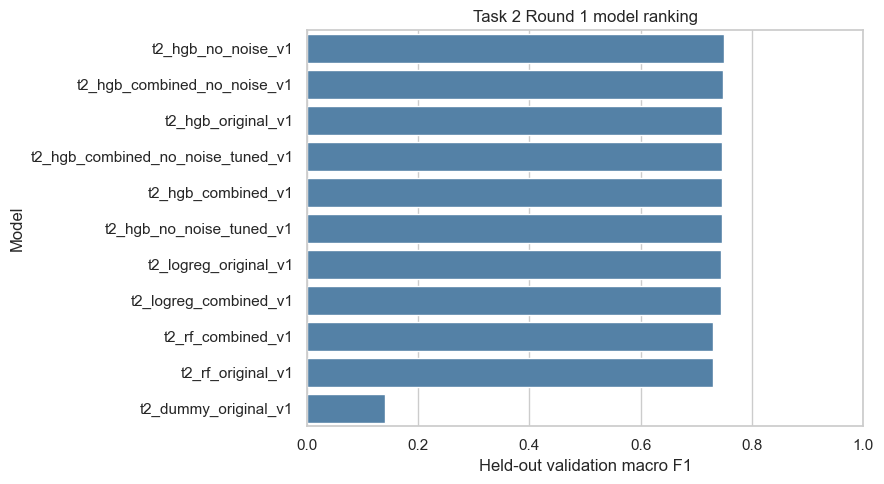

,configuration,original_F1,combined_F1,delta_combined_minus_original
0,logreg,0.74376,0.74355,-0.00020
1,rf,0.72933,0.72956,0.00023
2,hgb,0.74654,0.74559,-0.00095
3,hgb_no_noise,0.74944,0.74808,-0.00137
4,hgb_no_noise_tuned,0.74555,0.74636,0.00081


In [16]:
round1_names = [
    "t2_dummy_original_v1", "t2_logreg_original_v1",
    "t2_rf_original_v1", "t2_hgb_original_v1",
    "t2_hgb_no_noise_v1", "t2_hgb_no_noise_tuned_v1",
    "t2_logreg_combined_v1", "t2_rf_combined_v1",
    "t2_hgb_combined_v1", "t2_hgb_combined_no_noise_v1",
    "t2_hgb_combined_no_noise_tuned_v1",
]
index = read_evaluation_index(2)["evaluations"]
assert all(name in index for name in round1_names)
ranking_rows = []
for name in round1_names:
    data_name = json.loads(model_paths(name)[1].read_text(encoding="utf-8"))["data_name"]
    valid_X = X_valid if data_name == DATA_NAME else X_valid_combined
    pred = np.asarray(load_model(name).predict(valid_X)).reshape(-1)
    per_class = f1_score(y_valid, pred, labels=[0, 1, 2, 3], average=None,
                         zero_division=0)
    row = {"name": name, "dataset": data_name, "macro_F1": index[name]["score"]}
    row.update({f"F1_{label}": score for label, score in zip(
        ["casual", "grinder", "social", "whale"], per_class)})
    ranking_rows.append(row)
ranking = pd.DataFrame(ranking_rows).sort_values("macro_F1", ascending=False).reset_index(drop=True)
display(ranking.round(4))
print("Best Round 1 model:", ranking.iloc[0]["name"])
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=ranking, x="macro_F1", y="name", color="steelblue", ax=ax)
ax.set(xlim=(0, 1), xlabel="Held-out validation macro F1", ylabel="Model",
       title="Task 2 Round 1 model ranking")
plt.tight_layout()
plt.show()
# Matched deltas isolate the added features for otherwise identical settings.
pairs = [
    ("logreg", "t2_logreg_original_v1", "t2_logreg_combined_v1"),
    ("rf", "t2_rf_original_v1", "t2_rf_combined_v1"),
    ("hgb", "t2_hgb_original_v1", "t2_hgb_combined_v1"),
    ("hgb_no_noise", "t2_hgb_no_noise_v1", "t2_hgb_combined_no_noise_v1"),
    ("hgb_no_noise_tuned", "t2_hgb_no_noise_tuned_v1", "t2_hgb_combined_no_noise_tuned_v1"),
]
comparison = pd.DataFrame([
    {"configuration": label, "original_F1": index[old]["score"],
     "combined_F1": index[new]["score"],
     "delta_combined_minus_original": index[new]["score"] - index[old]["score"]}
    for label, old, new in pairs
])
display(comparison.round(5))

## 5. Inspect the leading model

Winner: t2_hgb_no_noise_v1
              precision    recall  f1-score   support

      Casual     0.7888    0.8554    0.8207      8187
     Grinder     0.7437    0.7352    0.7394      5207
      Social     0.7386    0.6897    0.7133      4203
       Whale     0.7691    0.6844    0.7243      3203

    accuracy                         0.7655     20800
   macro avg     0.7601    0.7412    0.7494     20800
weighted avg     0.7643    0.7655    0.7638     20800



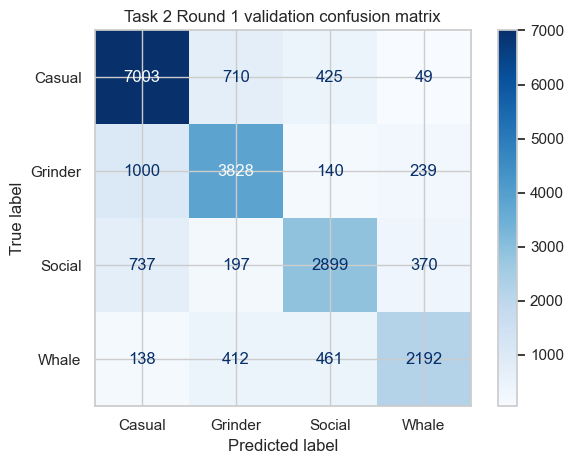

In [17]:
winner_name = ranking.iloc[0]["name"]
winner_model = load_model(winner_name)
winner_data_name = ranking.iloc[0]["dataset"]
X_winner_valid = X_valid if winner_data_name == DATA_NAME else X_valid_combined
winner_pred = np.asarray(winner_model.predict(X_winner_valid)).reshape(-1)
assert abs(f1_score(y_valid, winner_pred, average="macro") - ranking.iloc[0]["macro_F1"]) < 1e-12
print("Winner:", winner_name)
print(classification_report(y_valid, winner_pred,
                            target_names=["Casual", "Grinder", "Social", "Whale"],
                            digits=4, zero_division=0))
ConfusionMatrixDisplay.from_predictions(
    y_valid, winner_pred,
    display_labels=["Casual", "Grinder", "Social", "Whale"],
    cmap="Blues", values_format="d",
)
plt.title("Task 2 Round 1 validation confusion matrix")
plt.tight_layout()
plt.show()

Loaded permutation importance: t2_hgb_no_noise_v1


,feature,macro_F1_drop,std
0,loyalty_tier,0.2195,0.0035
1,engagement_level,0.0657,0.0056
2,vip_tier,0.0335,0.0036
3,days_since_last_login,0.0296,0.0014
4,total_playtime_hours,0.0267,0.0021
5,avg_monthly_spending,0.0250,0.0016
6,total_spending_thb,0.0206,0.0037
7,tournament_entries,0.0184,0.0025
8,chat_activity_score,0.0173,0.0034
9,friend_count,0.0171,0.0050


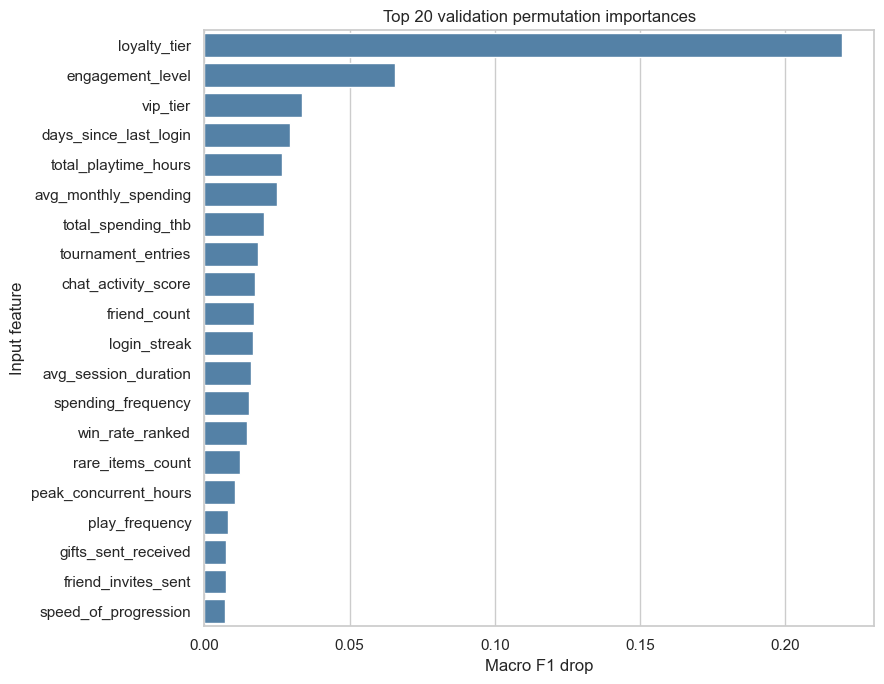

In [18]:
# Rank input columns, not one-hot output columns. Diagnostic only.
importance_path = SRC / "task2" / "models" / ".cache" / f"{winner_name}-permutation-v1.json"
model_path = model_paths(winner_name)[0]
cache_key = {"model_mtime_ns": model_path.stat().st_mtime_ns,
             "data_created_at": (data_card if winner_data_name == DATA_NAME else combined_card)["created_at"], "seed": SEED,
             "rows": 1500, "repeats": 2}
cached = json.loads(importance_path.read_text(encoding="utf-8")) if importance_path.exists() else None
if cached is not None and cached.get("key") == cache_key:
    feature_ranking = pd.DataFrame(cached["ranking"])
    print("Loaded permutation importance:", winner_name)
else:
    sample_idx = pd.Series(valid_idx).sample(n=1500, random_state=SEED).to_numpy()
    winner_train = train_df if winner_data_name == DATA_NAME else combined_train
    winner_feature_cols = feature_cols if winner_data_name == DATA_NAME else combined_feature_cols
    sample_X = winner_train.iloc[sample_idx][winner_feature_cols]
    sample_y = y.iloc[sample_idx]
    permutation = permutation_importance(winner_model, sample_X, sample_y,
                                         scoring=SCORE, n_repeats=2,
                                         random_state=SEED, n_jobs=1)
    feature_ranking = pd.DataFrame({
        "feature": winner_feature_cols, "macro_F1_drop": permutation.importances_mean,
        "std": permutation.importances_std,
    }).sort_values("macro_F1_drop", ascending=False).reset_index(drop=True)
    importance_path.parent.mkdir(parents=True, exist_ok=True)
    importance_path.write_text(json.dumps({"key": cache_key,
                                           "ranking": feature_ranking.to_dict("records")}, indent=2),
                               encoding="utf-8")
    print("Computed permutation importance:", winner_name)
display(feature_ranking.round(4))
fig, ax = plt.subplots(figsize=(9, 7))
sns.barplot(data=feature_ranking.head(20), x="macro_F1_drop", y="feature",
            color="steelblue", ax=ax)
ax.set(title="Top 20 validation permutation importances",
       xlabel="Macro F1 drop", ylabel="Input feature")
plt.tight_layout()
plt.show()

### Round 1 findings

The tables above are generated from saved evaluation artifacts on the same held-out rows. Use the matched `comparison` table to judge each feature change; the overall ranking alone mixes model choices and feature choices. The winner report and permutation ranking are diagnostic. Confirm any small gains with repeated folds before treating them as stable. `engagement_level` and `loyalty_tier` remain temporal availability caveats.